# Task 2 — Verificación por capas (Entrega parcial)
Grupo 5 — q = 0.20, D = 3 días. CC2017 Modelación y Simulación.

Cada capa se verifica por separado contra la teoría antes de acoplarlas. El código vive en `src/`; aquí
solo se ejecutan los experimentos, se guardan tablas en `resultados/` y gráficas en `figuras/`.
Todas las semillas son fijas (`np.random.default_rng([semilla, k])`).

In [1]:
import sys, pathlib, math
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.integrate import solve_ivp

ROOT = pathlib.Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
from des import simular_mmck, mmc_teoria, mmck_bloqueo, conteo_llegadas
from sd import Params, rhs, delta, umbral_U
from integradores import integrar
from hibrido import simular_hibrido, rho_fina, exposicion
from des import mmc_teoria

FIG, RES = ROOT / 'figuras', ROOT / 'resultados'
FIG.mkdir(exist_ok=True); RES.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .3,
                     'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})
P = Params()           # parámetros del grupo 5 (q = 0.20, D = 3)
N_REP = 50             # réplicas independientes (>= 30 pedidas)

def ic95(x):
    """Media e intervalo de confianza t de Student al 95 %: x̄ ± t_{0.975,n-1} s/√n."""
    x = np.asarray(x, float); n = len(x)
    return x.mean(), stats.t.ppf(0.975, n - 1) * x.std(ddof=1) / math.sqrt(n)

def replicas(lam, c, K, n=N_REP, tag=0, T=None, warm=None):
    return [simular_mmck(lam, c, P.mu, K, T or P.T_des, P.warm if warm is None else warm,
                         rng=np.random.default_rng([tag, i])) for i in range(n)]

## Task 2.1 — DES por separado contra la teoría M/M/c

**Fórmulas de clase.** A = λ/μ, ρ = λ/(cμ), Erlang C, W_q = C(c,A)/(cμ − λ), W = W_q + 1/μ y ley de Little
(L = λ W, L_q = λ W_q, servidores ocupados = λ/μ).

### 2.1a — λ = 6, c = 4, K muy grande (K = 10⁶)

In [2]:
teo_a = mmc_teoria(6.0, 4, P.mu)
rs_a = replicas(6.0, 4, 10**6, tag=21)
filas = []
for nombre, attr, valor in [('W (s)', 'W', teo_a['W']), ('Wq (s)', 'Wq', teo_a['Wq']),
                            ('Utilización ρ', 'util', teo_a['rho'])]:
    m, h = ic95([getattr(r, attr) for r in rs_a])
    filas.append({'métrica': nombre, 'simulado': m, 'IC95 inf': m - h, 'IC95 sup': m + h,
                  'teoría M/M/c': valor, 'error rel. %': 100 * (m - valor) / valor,
                  'teoría dentro del IC': bool(m - h <= valor <= m + h)})
t21a = pd.DataFrame(filas)
t21a.to_csv(RES / 'tabla_2_1a_mmc_vs_teoria.csv', index=False)
print('Teoría:', {k: round(v, 4) for k, v in teo_a.items()}, '| réplicas:', N_REP)
t21a.round(4)

Teoría: {'A': 3.0, 'rho': 0.75, 'C': 0.5094, 'Wq': 0.2547, 'W': 0.7547, 'Lq': 1.5283, 'L': 4.5283, 'ocupados': 3.0} | réplicas: 50


,métrica,simulado,IC95 inf,IC95 sup,teoría M/M/c,error rel. %,teoría dentro del IC
0,W (s),0.7585,0.7412,0.7758,0.7547,0.5016,True
1,Wq (s),0.2590,0.2434,0.2747,0.2547,1.6982,True
2,Utilización ρ,0.7492,0.7442,0.7543,0.7500,-0.1022,True


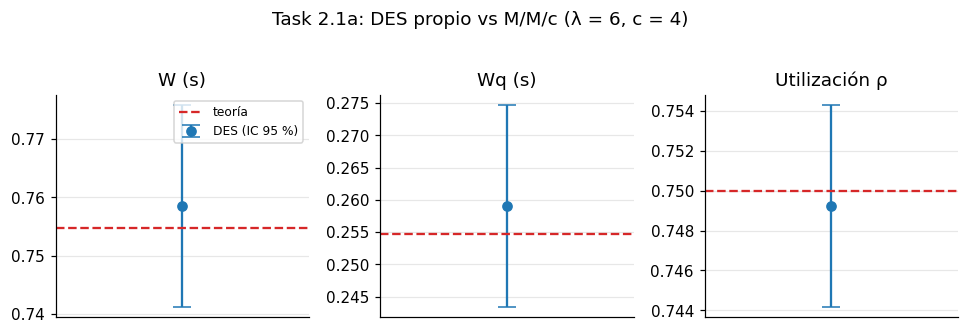

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(9, 2.9))
for a, (_, f) in zip(ax, t21a.iterrows()):
    a.errorbar([0], [f['simulado']], yerr=[[f['simulado'] - f['IC95 inf']], [f['IC95 sup'] - f['simulado']]],
               fmt='o', capsize=6, label='DES (IC 95 %)')
    a.axhline(f['teoría M/M/c'], color='C3', ls='--', label='teoría')
    a.set_xticks([]); a.set_title(f['métrica'])
ax[0].legend(fontsize=8)
fig.suptitle('Task 2.1a: DES propio vs M/M/c (λ = 6, c = 4)', y=1.03)
fig.tight_layout(); fig.savefig(FIG / 'fig_2_1a_des_vs_mmc.png', bbox_inches='tight'); plt.show()

**Interpretación 2.1a.** Las tres métricas simuladas quedan dentro de su IC 95 % y a menos de 1.7 % de la teoría; el DES reproduce M/M/c con ρ = 0.75.

### 2.1b — λ = 10, c = 4, K = 60 (sobrecarga)
Aquí ρ = λ/(cμ) = 1.25 > 1. Se compara la fracción rechazada simulada con la aproximación 1 − cμ/λ y con la
probabilidad de bloqueo **exacta** de M/M/c/K (proceso de nacimiento y muerte).

In [4]:
rs_b = replicas(10.0, 4, 60, tag=22)
m, h = ic95([r.r for r in rs_b])
aprox = 1 - 4 * P.mu / 10.0
exacto = mmck_bloqueo(10.0, 4, P.mu, 60)
t21b = pd.DataFrame([{'rechazo simulado': m, 'IC95 inf': m - h, 'IC95 sup': m + h,
                      '1 - cμ/λ': aprox, 'M/M/c/K exacto': exacto,
                      'aprox. dentro del IC': bool(m - h <= aprox <= m + h)}])
t21b.to_csv(RES / 'tabla_2_1b_rechazo.csv', index=False)
t21b.round(5)

,rechazo simulado,IC95 inf,IC95 sup,1 - cμ/λ,M/M/c/K exacto,aprox. dentro del IC
0,0.199,0.1949,0.2031,0.2,0.2,True


In [5]:
# ¿Cuándo falla 1 - cμ/λ? Comparación con el bloqueo exacto de M/M/c/K (c = 4, K = 60)
comp = pd.DataFrame([{'λ': l, 'ρ': l / 8, '1 - cμ/λ': max(0.0, 1 - 8 / l), 'M/M/c/K exacto': mmck_bloqueo(l, 4, P.mu, 60)}
                     for l in [6, 7, 7.5, 8, 8.5, 9, 10, 12, 20]])
comp.to_csv(RES / 'tabla_2_1b_aprox_vs_exacto.csv', index=False)
comp.round(5)

,λ,ρ,1 - cμ/λ,M/M/c/K exacto
0,6.0,0.7500,0.00000,0.00000
1,7.0,0.8750,0.00000,0.00005
2,7.5,0.9375,0.00000,0.00149
3,8.0,1.0000,0.00000,0.01689
4,8.5,1.0625,0.05882,0.06050
5,9.0,1.1250,0.11111,0.11122
6,10.0,1.2500,0.20000,0.20000
7,12.0,1.5000,0.33333,0.33333
8,20.0,2.5000,0.60000,0.60000


**Interpretación 2.1b.** El rechazo simulado (0.1990, IC [0.1949, 0.2031]) contiene a 1 − cμ/λ = 0.2 y al valor exacto de M/M/c/K (0.2000004).
1 − cμ/λ es solo una **aproximación**: supone que los 4 servidores están siempre ocupados, de modo que lo que sale del sistema es exactamente cμ y todo el exceso se rechaza.
En realidad el flujo atendido es λ(1 − P_K) ≤ cμ, porque a veces hay servidores ociosos, y K finito importa cuando ρ ≈ 1. Por eso 1 − cμ/λ es una cota inferior de P_K: con ρ = 1.25 la cola casi siempre está
llena y el error es del orden de 10⁻⁷, pero cerca de ρ = 1 la tabla muestra que la aproximación da 0 mientras el bloqueo real no lo es.

### 2.1c — Ley de Little con la simulación
Se compara cada cantidad medida directamente (promedio temporal en la parte medida) con la que da Little usando
la tasa de aceptación medida λ_ef y los tiempos medios medidos: L = λ_ef·W, L_q = λ_ef·W_q y servidores ocupados = λ_ef/μ.
El error relativo se calcula con las medias sobre las réplicas.

In [6]:
def little(rs):
    lam_ef = np.mean([r.lam_ef for r in rs])
    f = []
    for nom, directo, via in [
        ('L', np.mean([r.L for r in rs]), lam_ef * np.mean([r.W for r in rs])),
        ('Lq', np.mean([r.Lq for r in rs]), lam_ef * np.mean([r.Wq for r in rs])),
        ('servidores ocupados', np.mean([r.ocupados for r in rs]), lam_ef / P.mu)]:
        f.append({'cantidad': nom, 'medida directa': directo, 'vía Little': via,
                  'error relativo %': 100 * abs(directo - via) / via})
    return pd.DataFrame(f)

t21c_a = little(rs_a).assign(escenario='λ=6, c=4, K→∞')
t21c_b = little(rs_b).assign(escenario='λ=10, c=4, K=60')
t21c = pd.concat([t21c_a, t21c_b], ignore_index=True)
t21c.to_csv(RES / 'tabla_2_1c_little.csv', index=False)
assert (t21c['error relativo %'] < 3).all(), 'Little no se cumple dentro del 3 %'
t21c.round(4)

,cantidad,medida directa,vía Little,error relativo %,escenario
0,L,4.5537,4.5518,0.0408,"λ=6, c=4, K→∞"
1,Lq,1.5567,1.5545,0.1426,"λ=6, c=4, K→∞"
2,servidores ocupados,2.9969,3.0005,0.1200,"λ=6, c=4, K→∞"
3,L,55.9343,55.9546,0.0362,"λ=10, c=4, K=60"
4,Lq,51.9343,51.9538,0.0375,"λ=10, c=4, K=60"
5,servidores ocupados,4.0000,3.9968,0.0809,"λ=10, c=4, K=60"


**Interpretación 2.1c.** La ley de Little se cumple con errores relativos menores a 0.15 % en las tres cantidades y en ambos escenarios (también en sobrecarga, donde L ≈ 56 y los 4 servidores están ocupados).

## Task 2.2 — Capa SD por separado (δ = δ₀ constante)

Con δ = δ₀ la EDO es autónoma: dU/dt = (p + qU/M)(M − U) − δ₀U. Referencia: `solve_ivp` (RK45) con
rtol = atol = 10⁻¹⁰. Integradores propios: Euler (orden 1) y RK4 (orden 4), comparados en los nodos de cada malla.

In [7]:
f_sd = lambda U: rhs(U, P.delta0, P)
ref = solve_ivp(lambda t, y: [f_sd(y[0])], (0, 100), [P.U0], method='RK45',
                rtol=1e-10, atol=1e-10, dense_output=True)
hs = [2.0 ** (-k) for k in range(-2, 11)]          # 4, 2, 1, ..., 2^-10
filas = []
for h in hs:
    fila = {'h (días)': h}
    for met in ('euler', 'rk4'):
        t, U = integrar(f_sd, P.U0, 0.0, 100.0, h, met)
        fila[f'error máx {met}'] = np.max(np.abs(U - ref.sol(t)[0]))
    filas.append(fila)
t22 = pd.DataFrame(filas)
t22.to_csv(RES / 'tabla_2_2_error_vs_paso.csv', index=False)

# orden observado: pendiente de log(error) vs log(h) en la zona asintótica
h_arr = t22['h (días)'].values
e_eu, e_rk = t22['error máx euler'].values, t22['error máx rk4'].values
sel_eu = h_arr <= 0.5
sel_rk = (h_arr <= 2) & (e_rk > 1e-4)      # se excluye el piso de error de la referencia (~1e-5 usuarios)
p_eu = np.polyfit(np.log(h_arr[sel_eu]), np.log(e_eu[sel_eu]), 1)
p_rk = np.polyfit(np.log(h_arr[sel_rk]), np.log(e_rk[sel_rk]), 1)
print(f'Orden estimado Euler: {p_eu[0]:.3f} | RK4: {p_rk[0]:.3f}')
# Orden local entre pasos consecutivos (cociente de errores al reducir h a la mitad)
t22['orden local euler'] = np.log2(t22['error máx euler'].shift(1) / t22['error máx euler'])
t22['orden local rk4'] = np.log2(t22['error máx rk4'].shift(1) / t22['error máx rk4'])
t22.to_csv(RES / 'tabla_2_2_error_vs_paso.csv', index=False)
# El piso de RK4 (~1e-5) es el error de la propia referencia: se confirma con una referencia más estricta
ref2 = solve_ivp(lambda t, y: [f_sd(y[0])], (0, 100), [P.U0], rtol=1e-13, atol=1e-13, dense_output=True)
tt = np.linspace(0, 100, 2001)
print(f'|ref(1e-10) − ref(1e-13)| máx = {np.max(np.abs(ref.sol(tt)[0] - ref2.sol(tt)[0])):.2e} usuarios')
t22.round(6)

Orden estimado Euler: 0.999 | RK4: 3.885
|ref(1e-10) − ref(1e-13)| máx = 1.15e-05 usuarios


,h (días),error máx euler,error máx rk4,orden local euler,orden local rk4
0,4.000000,5050.930572,20.970169,NaN,NaN
1,2.000000,2659.935330,1.720904,0.925158,3.607100
2,1.000000,1369.491512,0.123162,0.957751,3.804542
3,0.500000,691.242746,0.008228,0.986376,3.903856
4,0.250000,347.086620,0.000535,0.993897,3.941772
5,0.125000,173.889461,0.000043,0.997125,3.638455
6,0.062500,87.032587,0.000014,0.998543,1.632538
7,0.031250,43.536822,0.000012,0.999320,0.218651
8,0.015625,21.773506,0.000012,0.999662,0.011059
9,0.007812,10.888031,0.000012,0.999831,-0.001990


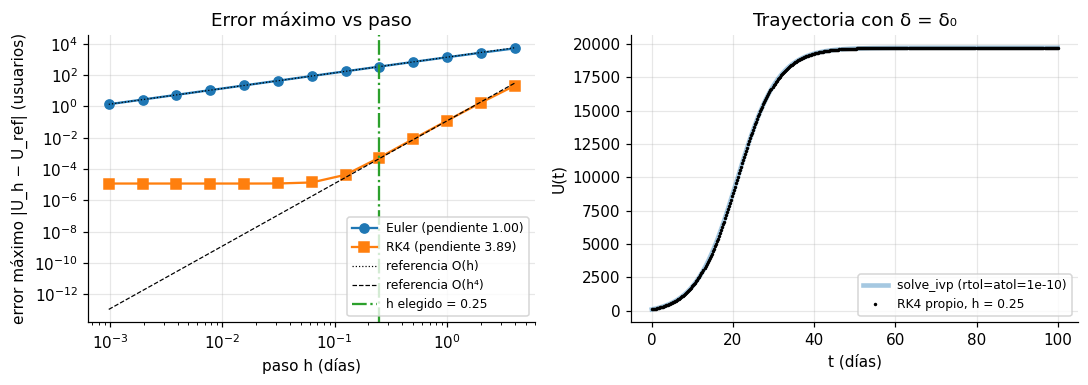

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].loglog(h_arr, e_eu, 'o-', label=f'Euler (pendiente {p_eu[0]:.2f})')
ax[0].loglog(h_arr, e_rk, 's-', label=f'RK4 (pendiente {p_rk[0]:.2f})')
hh = np.array([h_arr.min(), h_arr.max()])
ax[0].loglog(hh, np.exp(p_eu[1]) * hh ** 1, 'k:', lw=.8, label='referencia O(h)')
ax[0].loglog(hh, np.exp(p_rk[1]) * hh ** 4, 'k--', lw=.8, label='referencia O(h⁴)')
ax[0].axvline(0.25, color='C2', ls='-.', label='h elegido = 0.25')
ax[0].set_xlabel('paso h (días)'); ax[0].set_ylabel('error máximo |U_h − U_ref| (usuarios)')
ax[0].set_title('Error máximo vs paso'); ax[0].legend(fontsize=8)
t, U = integrar(f_sd, P.U0, 0.0, 100.0, 0.25, 'rk4')
tf = np.linspace(0, 100, 400)
ax[1].plot(tf, ref.sol(tf)[0], lw=3, alpha=.4, label='solve_ivp (rtol=atol=1e-10)')
ax[1].plot(t, U, 'k.', ms=2.5, label='RK4 propio, h = 0.25')
ax[1].set_xlabel('t (días)'); ax[1].set_ylabel('U(t)'); ax[1].set_title('Trayectoria con δ = δ₀'); ax[1].legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG / 'fig_2_2_convergencia_euler_rk4.png', bbox_inches='tight'); plt.show()

In [9]:
# Paso elegido para el resto de la hoja
H_RK4 = 0.25
err_elegido = float(t22.loc[t22['h (días)'] == H_RK4, 'error máx rk4'].iloc[0])
h_euler_equiv = (err_elegido / np.exp(p_eu[1])) ** (1 / p_eu[0])
print(f'RK4 con h = {H_RK4}: error máx = {err_elegido:.2e} usuarios ({100*err_elegido/P.M:.1e} % de M)')
print(f'Euler necesitaría h ≈ {h_euler_equiv:.1e} días ({100/h_euler_equiv:.2e} pasos) para igualar ese error')
assert err_elegido < 1e-2

RK4 con h = 0.25: error máx = 5.35e-04 usuarios (2.7e-06 % de M)
Euler necesitaría h ≈ 3.8e-07 días (2.63e+08 pasos) para igualar ese error


**Interpretación 2.2.** Euler tiene orden 1 (pendiente 0.999) y RK4 orden 4 (pendiente 3.89 en la zona asintótica). El piso de ≈1.2·10⁻⁵ usuarios en RK4 con pasos pequeños no es error de RK4: es el error de la propia referencia (|ref(10⁻¹⁰) − ref(10⁻¹³)| = 1.15·10⁻⁵). **Paso elegido: RK4 con h = 0.25 días** (error máximo 5.4·10⁻⁴ usuarios, ≈ 3·10⁻⁶ % de M, muy por debajo del ruido del DES); además 0.25 divide exactamente a todos los H de la hoja (0.25, 0.5, 1, 2, 4, 7) y a D = 3. Con Euler habría que usar pasos de ~10⁻⁷ días para el mismo error.

## Task 2.3 — Autoescalado como evento de estado bien localizado

* **(a) Versión con evento:** el cruce ρ_pred = θ ⇔ U = θcμ/a (11 200 con c = 4) se localiza *dentro* del paso por
  bisección sobre el paso RK4 (h = 0.25) y, como verificación, con `solve_ivp(events=...)`. La llegada de los servidores
  es un evento de tiempo exacto (pedido + D) y, si al llegar ρ_pred > θ, se reordena de inmediato.
* **(b) Versión ingenua:** ρ_pred se revisa solo al final de cada paso Δt (1 y 0.25 días); el pedido se emite en ese instante.

Para aislar el efecto de la detección, las tres versiones usan las **mismas semillas** del DES en cada intercambio.

In [10]:
SEMILLA = 2026
R = {
 'Evento (bisección)':       simular_hibrido(P, modo='evento', h_rk4=H_RK4, seed=SEMILLA),
 'Evento (solve_ivp)':       simular_hibrido(P, modo='evento', localizador='ivp', seed=SEMILLA),
 'Ingenua Δt = 1':           simular_hibrido(P, modo='ingenuo', dt=1.0, seed=SEMILLA),
 'Ingenua Δt = 0.25':        simular_hibrido(P, modo='ingenuo', dt=0.25, seed=SEMILLA)}

def w_teo_max(Rr):
    """Latencia M/M/c instantánea máxima a lo largo de la trayectoria fina (inf si ρ >= 1)."""
    idx = np.searchsorted(Rr['c_t'], Rr['t'], side='right') - 1
    w = [mmc_teoria(P.a * u, int(Rr['c_v'][i]), P.mu)['W'] if P.a * u < Rr['c_v'][i] * P.mu else np.inf
         for u, i in zip(Rr['U'], idx)]
    return max(w)

filas = []
for nom, Rr in R.items():
    filas.append({'versión': nom, 'día 1.er pedido': Rr['t_pedido1'], 'día de llegada': Rr['t_llegada1'],
                  'día 2.º pedido': Rr['pedidos'][1][0] if len(Rr['pedidos']) > 1 else np.nan,
                  'latencia máx W (s)': Rr['W_max'], 'U(100)': Rr['U_final'],
                  'servidores finales': Rr['c_final'], 'ρ_pred máx': exposicion(Rr, P)[0],
                  'días con ρ_pred > θ': exposicion(Rr, P)[1],
                  'W teórica máx (s)': w_teo_max(Rr)})
t23 = pd.DataFrame(filas)
t23.to_csv(RES / 'tabla_2_3_tres_versiones.csv', index=False)
dif = abs(R['Evento (bisección)']['t_pedido1'] - R['Evento (solve_ivp)']['t_pedido1'])
assert dif < 1e-5, dif
print(f'|t_pedido(bisección) − t_pedido(solve_ivp)| = {dif:.2e} días  (los dos localizadores coinciden)')
print('Umbral con c = 4:', umbral_U(4, P), 'usuarios')
t23.round(4)

|t_pedido(bisección) − t_pedido(solve_ivp)| = 5.38e-07 días  (los dos localizadores coinciden)
Umbral con c = 4: 11199.999999999998 usuarios


,versión,día 1.er pedido,día de llegada,día 2.º pedido,latencia máx W (s),U(100),servidores finales,ρ_pred máx,días con ρ_pred > θ,W teórica máx (s)
0,Evento (bisección),22.4209,25.4209,32.0567,0.9223,19703.0101,8,0.7928,6.00,0.852
1,Evento (solve_ivp),22.4209,25.4209,32.0567,0.9223,19703.0101,8,0.7928,6.00,0.852
2,Ingenua Δt = 1,23.0000,26.0000,33.0000,0.9223,19703.0101,8,0.7928,7.50,0.852
3,Ingenua Δt = 0.25,22.5000,25.5000,32.2500,0.9223,19703.0101,8,0.7928,6.26,0.852


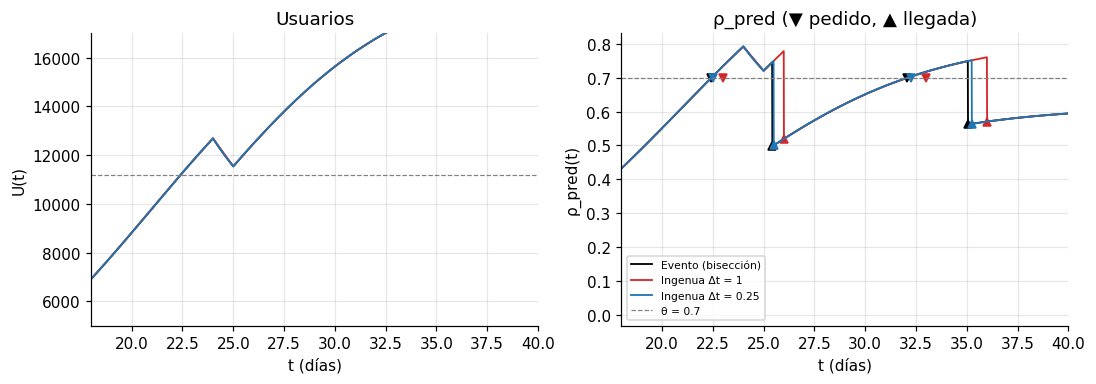

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6), sharex=True)
col = {'Evento (bisección)': 'k', 'Ingenua Δt = 1': 'C3', 'Ingenua Δt = 0.25': 'C0'}
for nom, cc in col.items():
    Rr = R[nom]; tf_, rho = rho_fina(Rr, P)
    ax[0].plot(Rr['t'], Rr['U'], color=cc, lw=1.2, label=nom)
    ax[1].plot(tf_, rho, color=cc, lw=1.2, label=nom)
    for (tp, _), (tl, _) in zip(Rr['pedidos'], Rr['llegadas']):
        ax[1].plot([tp], [P.theta], 'v', color=cc, ms=5); ax[1].plot([tl], [rho[np.searchsorted(tf_, tl)]], '^', color=cc, ms=5)
ax[1].axhline(P.theta, color='gray', ls='--', lw=.8, label='θ = 0.7')
ax[0].axhline(umbral_U(4, P), color='gray', ls='--', lw=.8)
for a in ax: a.set_xlim(18, 40); a.set_xlabel('t (días)')
ax[0].set_ylabel('U(t)'); ax[1].set_ylabel('ρ_pred(t)'); ax[0].set_ylim(5000, 17000)
ax[0].set_title('Usuarios'); ax[1].set_title('ρ_pred (▼ pedido, ▲ llegada)'); ax[1].legend(fontsize=7)
fig.tight_layout(); fig.savefig(FIG / 'fig_2_3_evento_vs_ingenua.png', bbox_inches='tight'); plt.show()

**Interpretación 2.3a-b.** Los dos localizadores (bisección y `solve_ivp`) dan el mismo instante de pedido (diferencia 5·10⁻⁷ días). La versión ingenua emite el pedido hasta el siguiente cierre de paso: +0.58 días con Δt = 1 y +0.08 con Δt = 0.25, y la llegada se retrasa lo mismo porque D es fijo.

In [12]:
# Réplicas con semillas distintas (20): diferencia pareada ingenua − evento
N23 = 20
filas = []
for s in range(N23):
    base = simular_hibrido(P, modo='evento', h_rk4=H_RK4, seed=100 + s)
    for nom, kw in [('Ingenua Δt = 1', dict(dt=1.0)), ('Ingenua Δt = 0.25', dict(dt=0.25))]:
        ing = simular_hibrido(P, modo='ingenuo', seed=100 + s, **kw)
        filas.append({'versión': nom, 'semilla': s,
                      'Δ día 1.er pedido': ing['t_pedido1'] - base['t_pedido1'],
                      'Δ día llegada': ing['t_llegada1'] - base['t_llegada1'],
                      'Δ latencia máx (s)': ing['W_max'] - base['W_max'],
                      'Δ U(100)': ing['U_final'] - base['U_final'],
                      'Δ ρ_pred máx': exposicion(ing, P)[0] - exposicion(base, P)[0],
                      'Δ días con ρ_pred > θ': exposicion(ing, P)[1] - exposicion(base, P)[1]})
rep23 = pd.DataFrame(filas)
res23 = rep23.groupby('versión').agg(['mean', 'std']).drop(columns='semilla')
res23.to_csv(RES / 'tabla_2_3_replicas_diferencias.csv')
res23.round(4)

Δ día 1.er pedido         Δ día llegada          \
                               mean     std          mean     std   
versión                                                             
Ingenua Δt = 0.25            0.0787  0.0015        0.0787  0.0015   
Ingenua Δt = 1               0.5787  0.0015        0.5787  0.0015   

                  Δ latencia máx (s)      Δ U(100)      Δ ρ_pred máx          \
                                mean  std     mean  std         mean     std   
versión                                                                        
Ingenua Δt = 0.25               -0.0  0.0      0.0  0.0       0.0007  0.0012   
Ingenua Δt = 1                  -0.0  0.0     -0.0  0.0       0.0068  0.0102   

                  Δ días con ρ_pred > θ          
                                   mean     std  
versión                                          
Ingenua Δt = 0.25                0.1795  0.0753  
Ingenua Δt = 1                   0.9775  0.2891

In [13]:
# (c) ¿Cuándo duele más la detección tardía? Barrido de crecimiento (q) y retraso de entrega (D),
# comparando evento vs ingenua Δt = 1 con las mismas semillas (3 por celda), con lazo cerrado y en cascada.
qs, Ds, N_S = [0.10, 0.20, 0.30, 0.40], [1.0, 3.0, 5.0], 3
filas = []
for lazo in (True, False):
    for q in qs:
        for D in Ds:
            Pq = P.con(q=q, D=D)
            for s in range(N_S):
                ev = simular_hibrido(Pq, modo='evento', h_rk4=H_RK4, lazo=lazo, seed=300 + s)
                ig = simular_hibrido(Pq, modo='ingenuo', dt=1.0, lazo=lazo, seed=300 + s)
                xe, xi = exposicion(ev, Pq), exposicion(ig, Pq)
                filas.append({'modelo': 'lazo cerrado' if lazo else 'cascada', 'q': q, 'D': D, 'semilla': s,
                              'ρ_pred máx (evento)': xe[0], 'Δ ρ_pred máx': xi[0] - xe[0],
                              'Δ días ρ_pred > θ': xi[1] - xe[1], 'Δ días ρ_pred ≥ 1': xi[2] - xe[2],
                              'Δ latencia máx (s)': ig['W_max'] - ev['W_max'], 'Δ rechazo máx': ig['r_max'] - ev['r_max'],
                              'Δ U(100)': ig['U_final'] - ev['U_final']})
sens = pd.DataFrame(filas)
tab_sens = sens.groupby(['modelo', 'q', 'D']).mean().drop(columns='semilla').reset_index()
tab_sens.to_csv(RES / 'tabla_2_3_sensibilidad_q_D.csv', index=False)
tab_sens.round(3)

,modelo,q,D,ρ_pred máx (evento),Δ ρ_pred máx,Δ días ρ_pred > θ,Δ días ρ_pred ≥ 1,Δ latencia máx (s),Δ rechazo máx,Δ U(100)
0,cascada,0.1,1.0,0.729,0.025,1.220,0.00,-0.000,0.000,-0.0
1,cascada,0.1,3.0,0.786,0.024,1.220,0.00,-0.000,0.000,-0.0
2,cascada,0.1,5.0,0.840,0.022,1.220,0.00,-0.000,0.000,-0.0
3,cascada,0.2,1.0,0.759,0.033,0.730,0.00,-0.000,0.000,-0.0
4,cascada,0.2,3.0,0.869,0.028,0.730,0.00,-0.000,0.000,-0.0
5,cascada,0.2,5.0,0.963,0.023,0.730,0.00,-0.000,0.000,-0.0
6,cascada,0.3,1.0,0.788,0.022,0.620,0.00,-0.000,0.000,-0.0
7,cascada,0.3,3.0,0.943,0.017,0.620,0.00,-0.000,0.000,-0.0
8,cascada,0.3,5.0,1.056,0.012,0.250,0.24,-0.032,-0.001,-0.0
9,cascada,0.4,1.0,0.816,0.087,1.000,0.00,-0.000,0.000,0.0


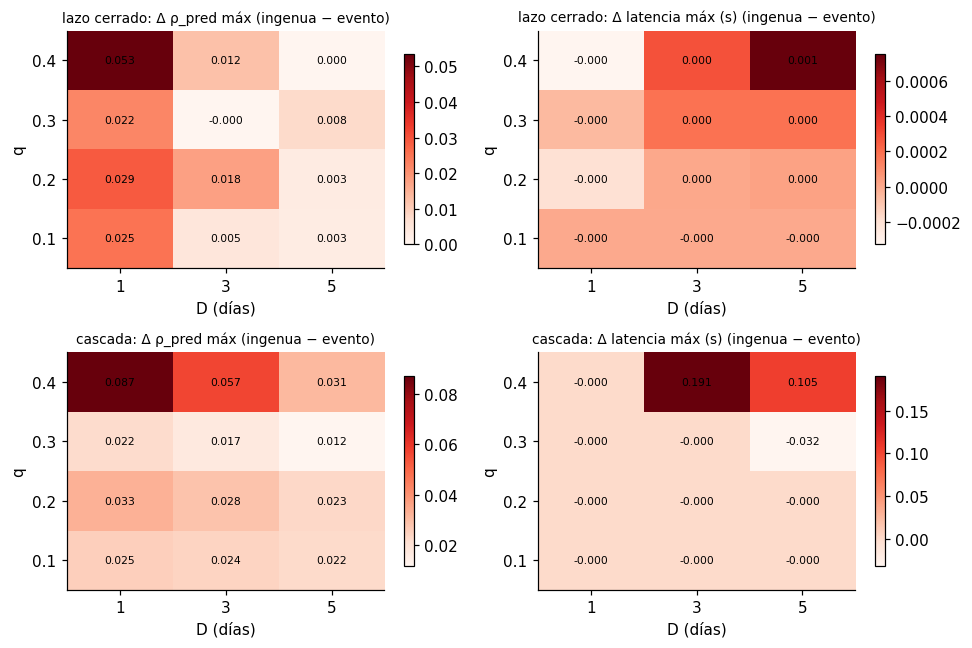

In [14]:
fig, ax = plt.subplots(2, 2, figsize=(9, 6))
for i, mod in enumerate(['lazo cerrado', 'cascada']):
    sub = tab_sens[tab_sens['modelo'] == mod]
    for j, (col, tit) in enumerate([('Δ ρ_pred máx', 'Δ ρ_pred máx'), ('Δ latencia máx (s)', 'Δ latencia máx (s)')]):
        M_ = sub.pivot(index='q', columns='D', values=col)
        im = ax[i, j].imshow(M_.values, origin='lower', aspect='auto', cmap='Reds')
        ax[i, j].set_xticks(range(len(Ds)), [f'{d:g}' for d in M_.columns]); ax[i, j].set_yticks(range(len(qs)), [f'{q:g}' for q in M_.index])
        ax[i, j].set_xlabel('D (días)'); ax[i, j].set_ylabel('q'); ax[i, j].set_title(f'{mod}: {tit} (ingenua − evento)', fontsize=9); ax[i, j].grid(False)
        for a_ in range(M_.shape[0]):
            for b_ in range(M_.shape[1]):
                ax[i, j].text(b_, a_, f'{M_.values[a_, b_]:.3f}', ha='center', va='center', fontsize=7)
        fig.colorbar(im, ax=ax[i, j], shrink=.8)
fig.tight_layout(); fig.savefig(FIG / 'fig_2_3_sensibilidad_q_D.png', bbox_inches='tight'); plt.show()

**Interpretación 2.3c (resumen; el desarrollo está en el documento).** En el caso base la detección tardía **no** cambia la latencia máxima ni U(100) (diferencias ~10⁻⁵ s y ~10⁻⁶ usuarios): el DES solo observa c en los instantes de intercambio (cada 1 día) y el abandono por latencia frena el crecimiento, así que ρ_pred sube a lo sumo a ≈ 0.79. Lo que sí cambia es el tiempo de exposición con ρ_pred > θ (+0.98 días con Δt = 1). El daño aparece cuando el crecimiento es rápido, D es largo y no hay freno: en la **cascada** con q = 0.4 y D ≥ 3 el sistema llega a ρ_pred ≥ 1 y la detección tardía añade 0.82 días de saturación, +0.19 s de latencia máxima y hasta +2 puntos porcentuales de rechazo.

## Task 2.4 — Interfaz entre capas

### 2.4a — Llegadas por ventana frente a un conteo de Poisson (λ = 5)
En cada una de 30 ventanas independientes se cuenta el número de llegadas en la parte medida (t ∈ [120, 720], 600 s).
Si las llegadas son Poisson(λ), el conteo es Poisson(λ·600 = 3000): media y varianza iguales a 3000.

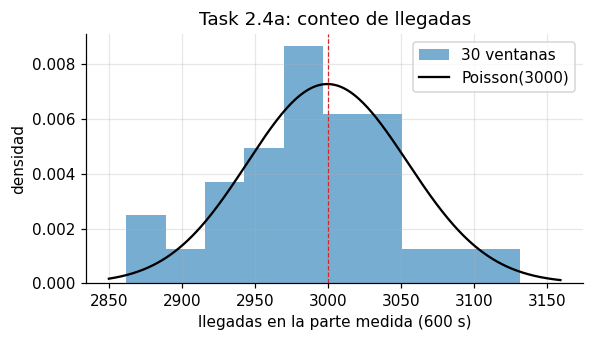

,λ·600 esperado,media muestral,IC95 media,varianza muestral,varianza/media,z (media),χ² dispersión (29 gl),p-valor dispersión
0,3000.0,2989.8333,±21.8,3403.7299,1.1384,-1.0167,33.0146,0.5543


In [15]:
LAM, NV = 5.0, 30
esperado = LAM * (P.T_des - P.warm)
cuentas = np.array([conteo_llegadas(LAM, P.T_des, P.warm, np.random.default_rng([24, i])) for i in range(NV)])
media, var = cuentas.mean(), cuentas.var(ddof=1)
z = (media - esperado) / math.sqrt(esperado / NV)              # media de 30 conteos ~ N(3000, 3000/30)
disp = (NV - 1) * var / media                                    # ~ χ²_{29} si es Poisson (índice de dispersión)
p_disp = 2 * min(stats.chi2.cdf(disp, NV - 1), stats.chi2.sf(disp, NV - 1))
t24a = pd.DataFrame([{'λ·600 esperado': esperado, 'media muestral': media, 'IC95 media': f'±{ic95(cuentas)[1]:.1f}',
                      'varianza muestral': var, 'varianza/media': var / media,
                      'z (media)': z, 'χ² dispersión (29 gl)': disp, 'p-valor dispersión': p_disp}])
t24a.to_csv(RES / 'tabla_2_4a_poisson.csv', index=False)
fig, ax = plt.subplots(figsize=(5.5, 3.2))
ax.hist(cuentas, bins=10, density=True, alpha=.6, label='30 ventanas')
xs = np.arange(2850, 3160); ax.plot(xs, stats.poisson.pmf(xs, esperado), 'k', label='Poisson(3000)')
ax.axvline(esperado, color='C3', ls='--', lw=.8)
ax.set_xlabel('llegadas en la parte medida (600 s)'); ax.set_ylabel('densidad'); ax.legend(); ax.set_title('Task 2.4a: conteo de llegadas')
fig.tight_layout(); fig.savefig(FIG / 'fig_2_4a_conteo_poisson.png', bbox_inches='tight'); plt.show()
t24a.round(4)

**Interpretación 2.4a.** La media de los conteos (2989.8) no difiere de λ·600 = 3000 (z = −1.02) y la varianza (3403.7) es consistente con la media: índice de dispersión 1.14 y χ²₂₉ = 33.0 (p = 0.55). No hay evidencia contra un proceso de Poisson.

### 2.4b — Conservación de entidades por ventana
En cada ventana completa de 720 s: **llegadas = atendidas + rechazadas + las que quedan dentro**.
Los cuatro contadores son independientes dentro del DES (llegadas al entrar, rechazadas al bloquear, atendidas al extraer
salidas, y las que quedan en el sistema al cerrar la ventana). Se usan 13 ventanas con c = 4, K = 60 y λ desde carga baja
hasta sobrecarga fuerte (cμ = 8).

In [16]:
filas = []
for i, lam in enumerate([1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 12, 15, 20]):
    r = simular_mmck(float(lam), 4, P.mu, P.K, P.T_des, P.warm, rng=np.random.default_rng([25, i]))
    filas.append({'ventana': i + 1, 'λ (1/s)': lam, 'ρ': lam / 8, 'llegadas': r.n_llegadas,
                  'atendidas': r.n_atendidas, 'rechazadas': r.n_rechazadas, 'dentro': r.n_dentro,
                  'balance': r.n_llegadas - (r.n_atendidas + r.n_rechazadas + r.n_dentro)})
t24b = pd.DataFrame(filas)
t24b.to_csv(RES / 'tabla_2_4b_conservacion.csv', index=False)
assert (t24b['balance'] == 0).all(), 'se viola la conservación de entidades'
t24b

,ventana,λ (1/s),ρ,llegadas,atendidas,rechazadas,dentro,balance
0,1,1,0.125,697,697,0,0,0
1,2,2,0.250,1454,1453,0,1,0
2,3,3,0.375,2196,2193,0,3,0
3,4,4,0.500,2889,2888,0,1,0
4,5,5,0.625,3665,3663,0,2,0
5,6,6,0.750,4277,4272,0,5,0
6,7,7,0.875,4991,4989,0,2,0
7,8,8,1.000,5604,5589,0,15,0
8,9,9,1.125,6497,5778,671,48,0
9,10,10,1.250,7166,5801,1306,59,0


**Interpretación 2.4b.** El balance es 0 en las 13 ventanas. En carga baja casi todo se atiende; desde ρ ≥ 1 aparecen rechazos y la cantidad que queda dentro se satura en K = 60 (ventanas λ = 15 y 20).

### 2.4c — Calentamiento de cada ventana y sesgo de empezar vacío
Regla: en cada intercambio el DES se reinicia vacío, simula 720 s y se **descartan las llegadas de los primeros 120 s**; las
métricas W y r usan solo las solicitudes que llegan entre 120 s y 720 s. Para cuantificar el sesgo de empezar vacío sin descartar
nada, se compara W con calentamiento 0 s y 120 s frente a la teoría M/M/c (K→∞, 400 réplicas pareadas), en carga moderada y alta.

In [17]:
# Mismas semillas con y sin calentamiento (diseño pareado): la diferencia aísla el sesgo de empezar vacío.
filas = []
for lam in [6.0, 7.5]:
    teo = mmc_teoria(lam, 4, P.mu)
    W0 = np.array([r.W for r in replicas(lam, 4, 10**6, n=400, tag=26, warm=0.0)])
    W1 = np.array([r.W for r in replicas(lam, 4, 10**6, n=400, tag=26, warm=120.0)])
    d, hd = ic95(W0 - W1)
    for warm, W_ in [(0.0, W0), (120.0, W1)]:
        m, h = ic95(W_)
        filas.append({'λ': lam, 'ρ': lam / 8, 'calentamiento (s)': warm, 'W simulado': m, 'IC95 ±': h,
                      'W teórico': teo['W'], 'sesgo %': 100 * (m - teo['W']) / teo['W'],
                      'W(sin cal.) − W(con cal.), IC95': f'{d:+.4f} ± {hd:.4f}' if warm == 0.0 else ''})
t24c = pd.DataFrame(filas)
t24c.to_csv(RES / 'tabla_2_4c_sesgo_calentamiento.csv', index=False)
t24c.round(4)

,λ,ρ,calentamiento (s),W simulado,IC95 ±,W teórico,sesgo %,"W(sin cal.) − W(con cal.), IC95"
0,6.0,0.7500,0.0,0.7555,0.0052,0.7547,0.0996,+0.0001 ± 0.0024
1,6.0,0.7500,120.0,0.7554,0.0055,0.7547,0.0924,
2,7.5,0.9375,0.0,2.1689,0.0756,2.2301,-2.7411,-0.0647 ± 0.0193
3,7.5,0.9375,120.0,2.2337,0.0859,2.2301,0.1617,


**Interpretación 2.4c.** Con ρ = 0.75 el calentamiento casi no importa (diferencia pareada +0.0001 ± 0.0024 s). Con ρ = 0.9375, empezar vacío sin descartar nada subestima W: −2.7 % frente a la teoría, y la diferencia pareada con/sin calentamiento es −0.065 ± 0.019 s, significativa. Descartar 120 s deja el sesgo en +0.16 %. El sesgo crece con ρ porque el sistema tarda más en llegar al régimen estacionario, y siempre es hacia abajo porque al inicio no hay cola.